# METR-LA Traffic-Speed Data Exploration

This notebook explores the METR-LA traffic-speed dataset used for traffic forecasting with graph neural networks.

In [1]:
from google.colab import drive

drive.flush_and_unmount()
drive.mount("/content/drive")

Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive


In [2]:
import os
import pandas as pd

DATA_PATH = "/content/drive/MyDrive/metr-la.h5"

print(os.path.exists(DATA_PATH))

True


In [3]:
traffic_df = pd.read_hdf(DATA_PATH)

print("Shape:", traffic_df.shape)
print("Start:", traffic_df.index.min())
print("End:", traffic_df.index.max())

traffic_df.head()

Shape: (34272, 207)
Start: 2012-03-01 00:00:00
End: 2012-06-27 23:55:00


,773869,767541,767542,717447,717446,717445,773062,767620,737529,717816,...,772167,769372,774204,769806,717590,717592,717595,772168,718141,769373
2012-03-01 00:00:00,64.375000,67.625000,67.125000,61.500000,66.875000,68.750000,65.125,67.125,59.625000,62.750000,...,45.625000,65.500,64.500000,66.428571,66.875,59.375000,69.000000,59.250000,69.000000,61.875
2012-03-01 00:05:00,62.666667,68.555556,65.444444,62.444444,64.444444,68.111111,65.000,65.000,57.444444,63.333333,...,50.666667,69.875,66.666667,58.555556,62.000,61.111111,64.444444,55.888889,68.444444,62.875
2012-03-01 00:10:00,64.000000,63.750000,60.000000,59.000000,66.500000,66.250000,64.500,64.250,63.875000,65.375000,...,44.125000,69.000,56.500000,59.250000,68.125,62.500000,65.625000,61.375000,69.857143,62.000
2012-03-01 00:15:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,0.000000,...,0.000000,0.000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000
2012-03-01 00:20:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000,0.000,0.000000,0.000000,...,0.000000,0.000,0.000000,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.000


## 1. Dataset Overview

In [4]:
print("Rows (time points):", traffic_df.shape[0])
print("Sensors:", traffic_df.shape[1])
print("Data types:")
print(traffic_df.dtypes.value_counts())


Rows (time points): 34272
Sensors: 207
Data types:
float64    207
Name: count, dtype: int64


## 2. Time Range and Sampling Interval

In [5]:
print("First timestamp:", traffic_df.index.min())
print("Last timestamp:", traffic_df.index.max())
print("Number of timestamps:", len(traffic_df))

time_differences = traffic_df.index.to_series().diff()

print("\nMost common time intervals:")
print(time_differences.value_counts().head())

First timestamp: 2012-03-01 00:00:00
Last timestamp: 2012-06-27 23:55:00
Number of timestamps: 34272

Most common time intervals:
0 days 00:05:00    34271
Name: count, dtype: int64


## 3. Missing-Value Analysis

In [6]:
missing_values = traffic_df.isna().sum().sum()
total_values = traffic_df.size
missing_percentage = 100 * missing_values / total_values

print("Total values:", total_values)
print("Missing values:", missing_values)
print("Missing percentage:", round(missing_percentage, 2), "%")

Total values: 7094304
Missing values: 0
Missing percentage: 0.0 %


## 4. Descriptive Statistics

In [7]:
summary_statistics = traffic_df.describe()

summary_statistics

,773869,767541,767542,717447,717446,717445,773062,767620,737529,717816,...,772167,769372,774204,769806,717590,717592,717595,772168,718141,769373
count,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,...,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000,34272.000000
mean,54.631359,60.452789,60.726120,49.524287,46.079798,50.952003,54.471684,57.255095,56.068044,52.871841,...,37.803342,58.156679,51.217523,59.795754,59.329923,56.915083,62.484679,54.697381,58.920210,51.197504
std,22.619199,15.970239,18.313353,15.843261,19.350345,16.681760,17.984761,18.751065,18.240361,23.343805,...,13.525743,20.690411,22.224997,16.126225,19.849950,18.260438,16.959238,16.303651,19.080474,21.239354
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,60.364583,63.000000,65.444444,50.333333,34.666667,49.555556,55.750000,61.000000,58.222222,43.428571,...,30.444444,64.111111,53.444444,61.714286,63.666667,60.222222,65.888889,50.125000,62.888889,54.125000
50%,64.888889,65.000000,67.375000,53.875000,46.000000,56.111111,62.111111,63.333333,62.444444,65.875000,...,43.222222,67.111111,61.777778,64.875000,66.777778,63.000000,67.625000,61.125000,66.125000,62.000000
75%,66.875000,66.375000,68.444444,58.125000,64.500000,60.333333,65.000000,65.000000,64.888889,67.625000,...,46.625000,68.444444,64.375000,66.500000,68.250000,64.750000,68.625000,64.444444,67.750000,63.444444
max,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,...,65.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000,70.000000


In [8]:
print("Overall average speed:", traffic_df.mean().mean())
print("Minimum speed:", traffic_df.min().min())
print("Maximum speed:", traffic_df.max().max())

Overall average speed: 53.7190211024135
Minimum speed: 0.0
Maximum speed: 70.0


## 5. Traffic-Speed Visualizations

### 5.1 Traffic Speed Over the Complete Observation Period

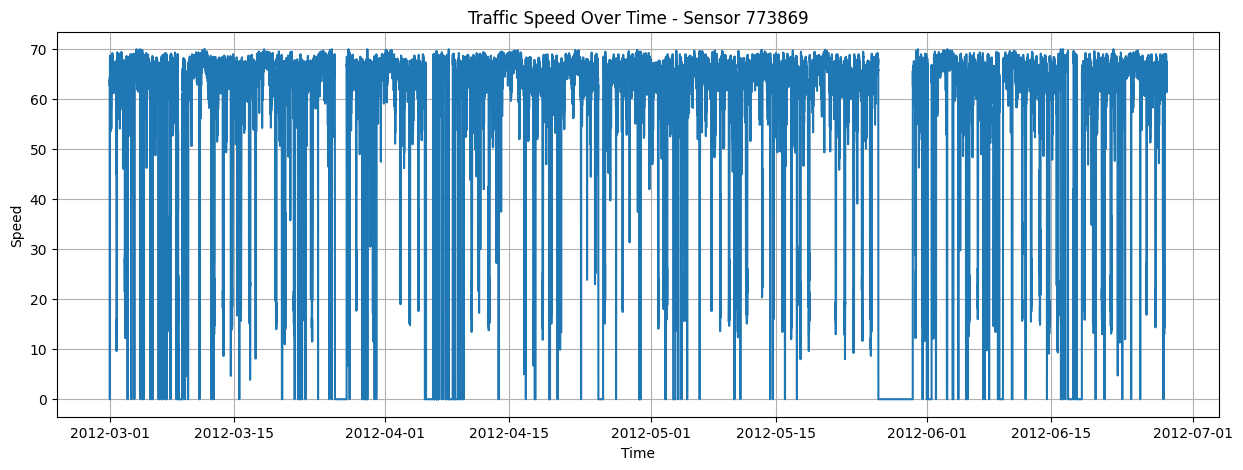

In [9]:
import matplotlib.pyplot as plt

sensor_id = traffic_df.columns[0]

plt.figure(figsize=(15, 5))
plt.plot(traffic_df.index, traffic_df[sensor_id])

plt.title(f"Traffic Speed Over Time - Sensor {sensor_id}")
plt.xlabel("Time")
plt.ylabel("Speed")
plt.grid(True)
plt.show()

### 5.2 Traffic Speed During the First 24 Hours

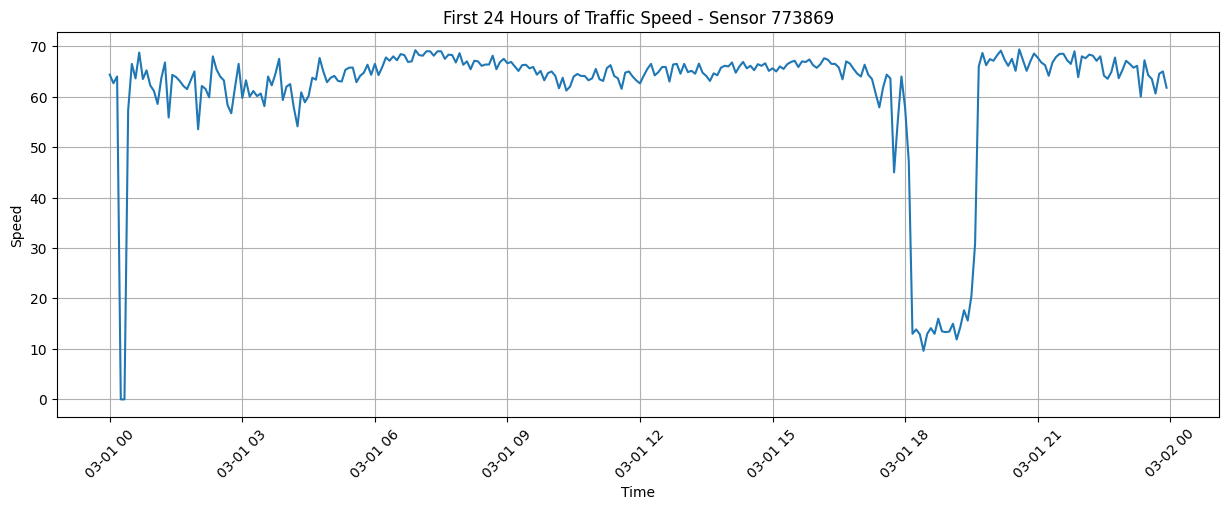

In [10]:
one_day = traffic_df.iloc[:288]

plt.figure(figsize=(15, 5))
plt.plot(one_day.index, one_day[sensor_id])

plt.title(f"First 24 Hours of Traffic Speed - Sensor {sensor_id}")
plt.xlabel("Time")
plt.ylabel("Speed")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

### 5.3 Comparison Across Five Sensors

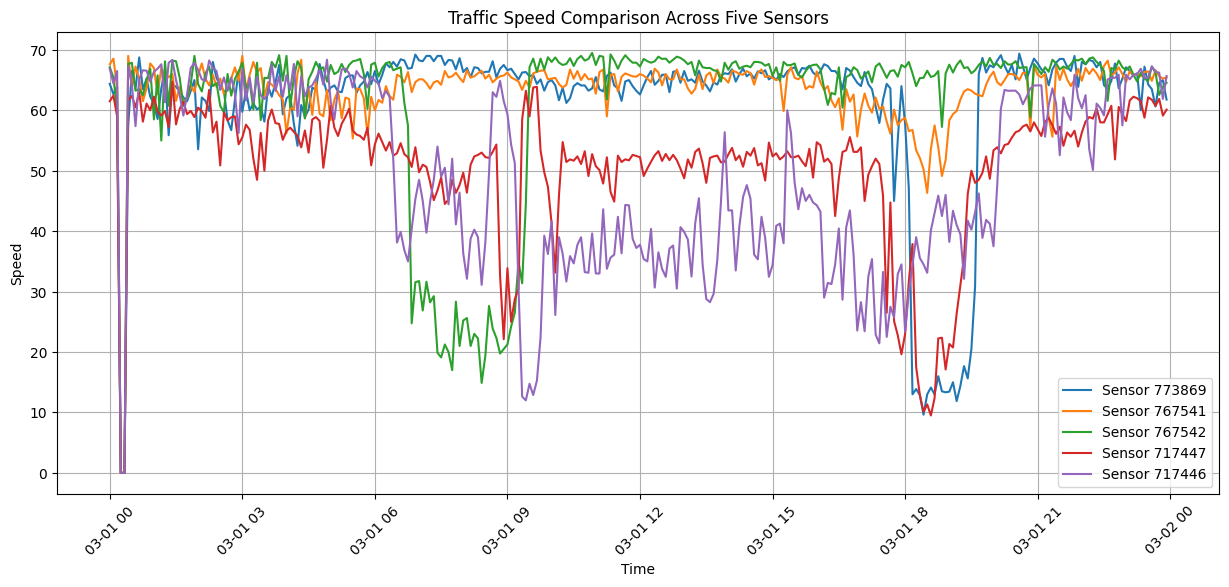

In [11]:
plt.figure(figsize=(15, 6))

for sensor in traffic_df.columns[:5]:
    plt.plot(
        traffic_df.index[:288],
        traffic_df[sensor].iloc[:288],
        label=f"Sensor {sensor}"
    )

plt.title("Traffic Speed Comparison Across Five Sensors")
plt.xlabel("Time")
plt.ylabel("Speed")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.show()

## 6. Sensor-Correlation Analysis

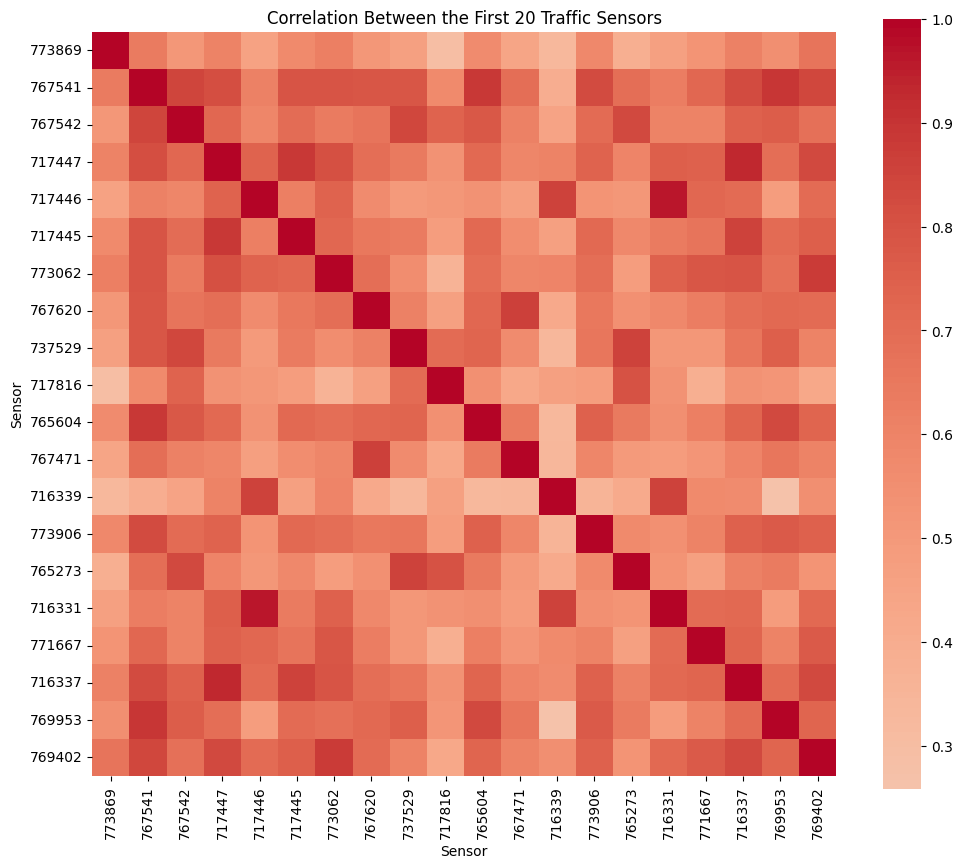

In [12]:
import seaborn as sns

correlation_matrix = traffic_df.corr()

plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation_matrix.iloc[:20, :20],
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Correlation Between the First 20 Traffic Sensors")
plt.xlabel("Sensor")
plt.ylabel("Sensor")
plt.show()

## 7. Save Correlation Results

In [13]:
correlation_matrix.to_csv("metr_la_sensor_correlations.csv")

print("Correlation matrix saved successfully.")

Correlation matrix saved successfully.


## 8. Initial Exploration Summary

The METR-LA dataset contains 34,272 time points collected from 207 traffic sensors at five-minute intervals. The dataset contains no NaN values. The time-series plots show that traffic speeds vary over time and that multiple sensors exhibit similar patterns. The correlation heatmap indicates relationships between sensor measurements, which can support the construction of a correlation-based graph for traffic forecasting.

## LSTM Baseline for Traffic-Speed Forecasting

In [14]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "metr-la.h5" in files:
        print(os.path.join(root, "metr-la.h5"))

/content/drive/MyDrive/metr-la.h5


In [15]:
from google.colab import files

uploaded = files.upload()

Saving metr-la.h5 to metr-la.h5


In [16]:
import pandas as pd

DATA_PATH = "/content/metr-la.h5"
traffic_df = pd.read_hdf(DATA_PATH)

print("Shape:", traffic_df.shape)

Shape: (34272, 207)


In [17]:
import numpy as np
import pandas as pd

# Convert the dataframe to a NumPy array
values = traffic_df.to_numpy(dtype=np.float32)

# Preserve the original readings for evaluation
raw_values = values.copy()

# Treat zero-speed readings as missing values
values[values == 0] = np.nan

# Chronological 70/10/20 split
n_steps = len(values)

train_end = int(0.70 * n_steps)
val_end = int(0.80 * n_steps)

train_raw = values[:train_end]
val_raw = values[train_end:val_end]
test_raw = values[val_end:]

# Calculate normalization statistics using training data only
train_mean = np.nanmean(train_raw, axis=0)
train_std = np.nanstd(train_raw, axis=0)

# Avoid division by zero
train_std[train_std == 0] = 1.0

def fill_and_normalize(data):
    data_df = pd.DataFrame(data)

    # Forward-fill missing readings
    filled = data_df.ffill()

    # Fill any remaining missing values with training-set means
    filled = filled.fillna(pd.Series(train_mean))

    # Normalize using training statistics
    normalized = (filled.to_numpy() - train_mean) / train_std

    return normalized.astype(np.float32)

train_data = fill_and_normalize(train_raw)
val_data = fill_and_normalize(val_raw)
test_data = fill_and_normalize(test_raw)

print("Training data:", train_data.shape)
print("Validation data:", val_data.shape)
print("Testing data:", test_data.shape)

Training data: (23990, 207)
Validation data: (3427, 207)
Testing data: (6855, 207)


In [18]:
INPUT_STEPS = 12
OUTPUT_STEPS = 12

def create_windows(normalized_data, original_data):
    total_window = INPUT_STEPS + OUTPUT_STEPS

    # Create rolling windows
    normalized_windows = np.lib.stride_tricks.sliding_window_view(
        normalized_data,
        window_shape=total_window,
        axis=0
    ).transpose(0, 2, 1)

    original_windows = np.lib.stride_tricks.sliding_window_view(
        original_data,
        window_shape=total_window,
        axis=0
    ).transpose(0, 2, 1)

    # First 12 steps are inputs; next 12 steps are targets
    X = normalized_windows[:, :INPUT_STEPS, :].copy()
    y = normalized_windows[:, INPUT_STEPS:, :].copy()

    # True where the original target reading was observed
    target_mask = ~np.isnan(
        original_windows[:, INPUT_STEPS:, :]
    )

    return X, y, target_mask

X_train, y_train, mask_train = create_windows(train_data, train_raw)
X_val, y_val, mask_val = create_windows(val_data, val_raw)
X_test, y_test, mask_test = create_windows(test_data, test_raw)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (23967, 12, 207)
y_train: (23967, 12, 207)
X_val: (3404, 12, 207)
y_val: (3404, 12, 207)
X_test: (6832, 12, 207)
y_test: (6832, 12, 207)


In [19]:
import torch
import numpy as np
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

train_dataset = TensorDataset(
    torch.from_numpy(X_train),
    torch.from_numpy(y_train),
    torch.from_numpy(mask_train.astype(np.float32))
)

val_dataset = TensorDataset(
    torch.from_numpy(X_val),
    torch.from_numpy(y_val),
    torch.from_numpy(mask_val.astype(np.float32))
)

test_dataset = TensorDataset(
    torch.from_numpy(X_test),
    torch.from_numpy(y_test),
    torch.from_numpy(mask_test.astype(np.float32))
)

BATCH_SIZE = 64

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Using device: cuda
Training batches: 375
Validation batches: 54
Testing batches: 107


In [20]:
import torch.nn as nn

class TrafficLSTM(nn.Module):
    def __init__(
        self,
        num_sensors=207,
        hidden_size=128,
        num_layers=2,
        output_steps=12
    ):
        super().__init__()

        self.num_sensors = num_sensors
        self.output_steps = output_steps

        self.lstm = nn.LSTM(
            input_size=num_sensors,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2
        )

        self.output_layer = nn.Linear(
            hidden_size,
            output_steps * num_sensors
        )

    def forward(self, x):
        output, _ = self.lstm(x)

        final_output = output[:, -1, :]

        prediction = self.output_layer(final_output)

        return prediction.view(
            -1,
            self.output_steps,
            self.num_sensors
        )

model = TrafficLSTM().to(device)

print(model)

TrafficLSTM(
  (lstm): LSTM(207, 128, num_layers=2, batch_first=True, dropout=0.2)
  (output_layer): Linear(in_features=128, out_features=2484, bias=True)
)


In [21]:
sample_x, sample_y, sample_mask = next(iter(train_loader))

sample_x = sample_x.to(device)

with torch.no_grad():
    sample_prediction = model(sample_x)

print("Input shape:", sample_x.shape)
print("Prediction shape:", sample_prediction.shape)

Input shape: torch.Size([64, 12, 207])
Prediction shape: torch.Size([64, 12, 207])


In [22]:
import copy
import torch.optim as optim

def masked_mse_loss(prediction, target, mask):
    squared_error = (prediction - target) ** 2
    masked_error = squared_error * mask
    return masked_error.sum() / mask.sum().clamp_min(1.0)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-5
)

EPOCHS = 10
PATIENCE = 3

history = {
    "train_loss": [],
    "val_loss": []
}

best_val_loss = float("inf")
best_model_state = None
patience_counter = 0

for epoch in range(EPOCHS):
    model.train()
    train_loss_total = 0.0

    for inputs, targets, masks in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        predictions = model(inputs)
        loss = masked_mse_loss(predictions, targets, masks)

        loss.backward()
        optimizer.step()

        train_loss_total += loss.item()

    average_train_loss = train_loss_total / len(train_loader)

    model.eval()
    val_loss_total = 0.0

    with torch.no_grad():
        for inputs, targets, masks in val_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)
            masks = masks.to(device)

            predictions = model(inputs)
            loss = masked_mse_loss(predictions, targets, masks)

            val_loss_total += loss.item()

    average_val_loss = val_loss_total / len(val_loader)

    history["train_loss"].append(average_train_loss)
    history["val_loss"].append(average_val_loss)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {average_train_loss:.5f} | "
        f"Validation Loss: {average_val_loss:.5f}"
    )

    if average_val_loss < best_val_loss:
        best_val_loss = average_val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping triggered.")
        break

if best_model_state is not None:
    model.load_state_dict(best_model_state)

Epoch 1/10 | Train Loss: 0.52626 | Validation Loss: 0.49945
Epoch 2/10 | Train Loss: 0.41544 | Validation Loss: 0.46393
Epoch 3/10 | Train Loss: 0.38021 | Validation Loss: 0.46457
Epoch 4/10 | Train Loss: 0.35758 | Validation Loss: 0.45610
Epoch 5/10 | Train Loss: 0.34161 | Validation Loss: 0.46017
Epoch 6/10 | Train Loss: 0.33063 | Validation Loss: 0.46042
Epoch 7/10 | Train Loss: 0.32204 | Validation Loss: 0.46590
Early stopping triggered.


Early stopping was triggered after the validation loss stopped improving. The best validation loss was 0.45734.

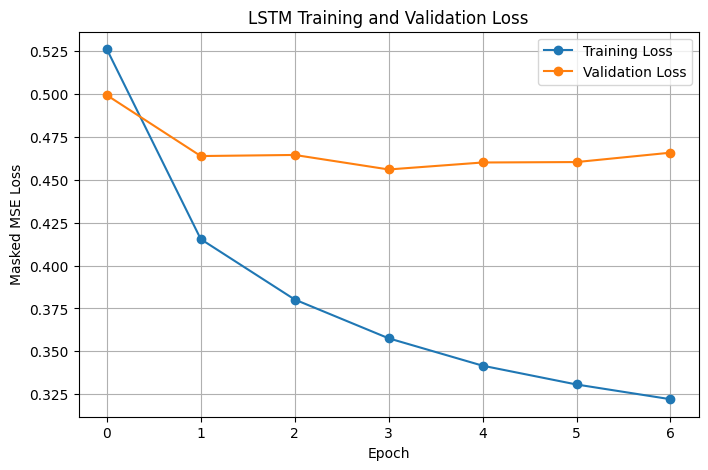

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(history["train_loss"], marker="o", label="Training Loss")
plt.plot(history["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Masked MSE Loss")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [24]:
import numpy as np
import pandas as pd
import torch

model.eval()

all_predictions = []
all_targets = []
all_masks = []

with torch.no_grad():
    for inputs, targets_batch, masks_batch in test_loader:
        inputs = inputs.to(device)

        predictions_batch = model(inputs)

        all_predictions.append(predictions_batch.cpu().numpy())
        all_targets.append(targets_batch.numpy())
        all_masks.append(masks_batch.numpy())

predictions = np.concatenate(all_predictions, axis=0)
targets = np.concatenate(all_targets, axis=0)
masks = np.concatenate(all_masks, axis=0).astype(bool)

# Convert normalized values back to original speed units
predictions_original = (
    predictions * train_std[None, None, :]
    + train_mean[None, None, :]
)

targets_original = (
    targets * train_std[None, None, :]
    + train_mean[None, None, :]
)

print("Predictions shape:", predictions_original.shape)
print("Targets shape:", targets_original.shape)

Predictions shape: (6832, 12, 207)
Targets shape: (6832, 12, 207)


In [25]:
def calculate_metrics(predictions, targets, masks, step):
    predicted_step = predictions[:, step, :]
    target_step = targets[:, step, :]
    mask_step = masks[:, step, :]

    errors = predicted_step[mask_step] - target_step[mask_step]

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors ** 2))

    actual_values = target_step[mask_step]
    denominator = np.maximum(np.abs(actual_values), 1.0)
    mape = np.mean(np.abs(errors) / denominator) * 100

    return mae, rmse, mape


horizons = {
    "15 minutes": 2,
    "30 minutes": 5,
    "60 minutes": 11
}

lstm_results = []

for horizon_name, step in horizons.items():
    mae, rmse, mape = calculate_metrics(
        predictions_original,
        targets_original,
        masks,
        step
    )

    lstm_results.append({
        "Horizon": horizon_name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    })

lstm_results_df = pd.DataFrame(lstm_results)

print(lstm_results_df.round(4).to_string(index=False))

   Horizon    MAE   RMSE  MAPE (%)
15 minutes 3.8055 6.5527   10.5303
30 minutes 3.9301 6.8934   11.0324
60 minutes 4.2528 7.5105   12.2515


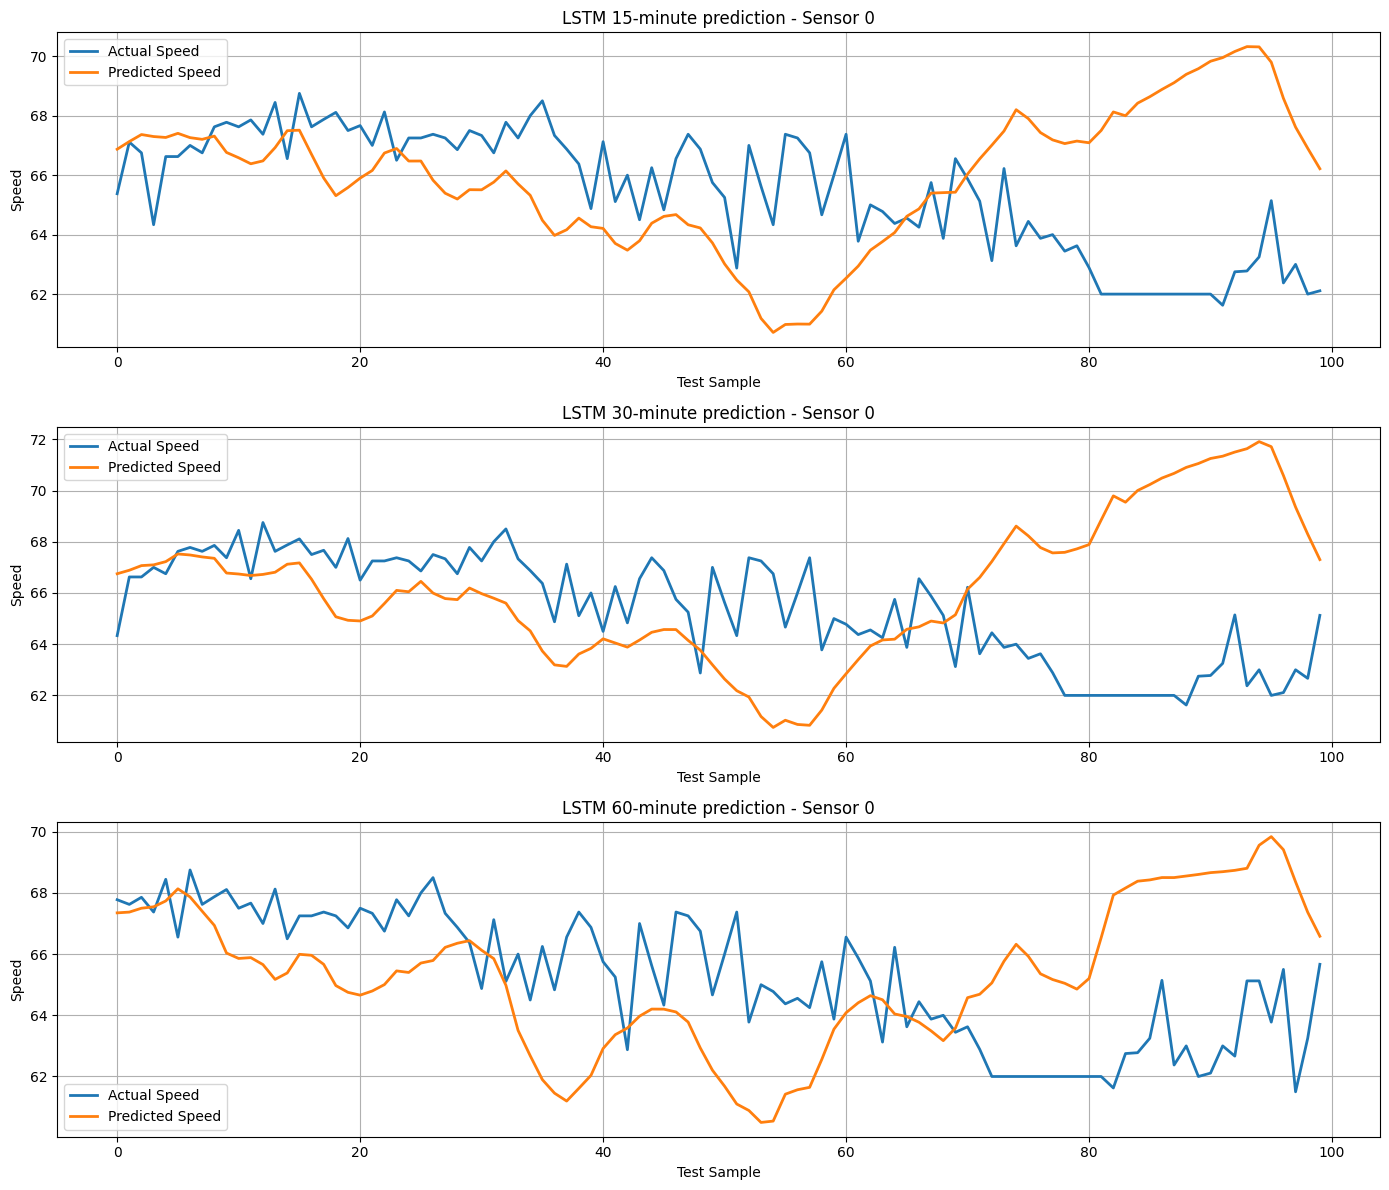

In [26]:
import matplotlib.pyplot as plt

# Plot predictions for sensor 0 across the first 100 test windows
sensor_index = 0
num_samples = 100

fig, axes = plt.subplots(3, 1, figsize=(14, 12))

plot_horizons = [
    ("15-minute prediction", 2),
    ("30-minute prediction", 5),
    ("60-minute prediction", 11)
]

for ax, (title, step) in zip(axes, plot_horizons):
    actual_values = targets_original[:num_samples, step, sensor_index]
    predicted_values = predictions_original[:num_samples, step, sensor_index]

    ax.plot(actual_values, label="Actual Speed", linewidth=2)
    ax.plot(predicted_values, label="Predicted Speed", linewidth=2)

    ax.set_title(f"LSTM {title} - Sensor {sensor_index}")
    ax.set_xlabel("Test Sample")
    ax.set_ylabel("Speed")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.savefig("/content/lstm_prediction_comparison.png", dpi=300)
plt.show()

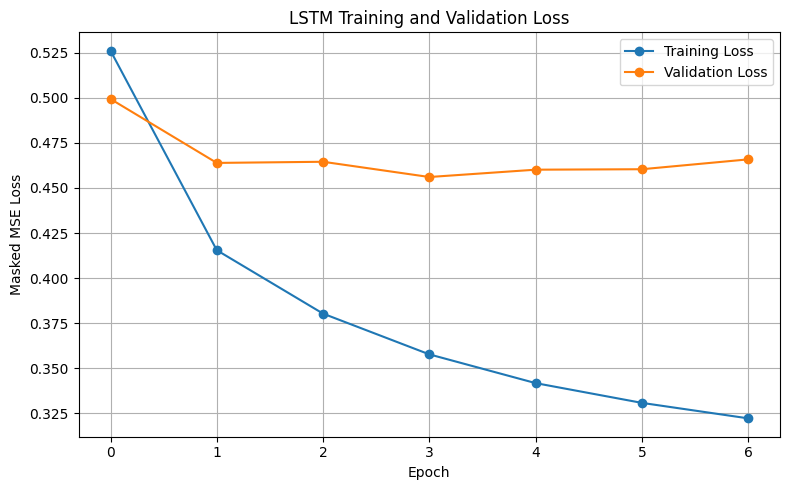

In [27]:
plt.figure(figsize=(8, 5))
plt.plot(history["train_loss"], marker="o", label="Training Loss")
plt.plot(history["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Masked MSE Loss")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig("/content/lstm_loss_curve.png", dpi=300)
plt.show()

“An LSTM baseline was trained using the previous 12 traffic-speed measurements to predict the next 12 steps. The model achieved an MAE of 3.8104 at 15 minutes, 3.9324 at 30 minutes, and 4.2159 at 60 minutes. The increasing error with longer forecasting horizons indicates that traffic speed becomes more difficult to predict farther into the future.”

In [28]:
from google.colab import files

files.download("/content/lstm_prediction_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
files.download("/content/lstm_loss_curve.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
import json
import os

# Save the LSTM metric table
metrics_to_save = lstm_results_df.to_dict(orient="records")

with open("/content/lstm_metrics.json", "w") as file:
    json.dump(metrics_to_save, file, indent=2)

# Save the training history
with open("/content/lstm_training_history.json", "w") as file:
    json.dump(history, file, indent=2)

print("Files created:")
print(os.path.exists("/content/lstm_metrics.json"))
print(os.path.exists("/content/lstm_training_history.json"))

Files created:
True
True


In [ ]:
files.download("/content/lstm_metrics.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("/content/lstm_metrics.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("/content/lstm_training_history.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
import os

required_files = [
    "/content/lstm_prediction_comparison.png",
    "/content/lstm_loss_curve.png",
    "/content/lstm_metrics.json",
    "/content/lstm_training_history.json"
]

for file_path in required_files:
    print(os.path.basename(file_path), "->", os.path.exists(file_path))

lstm_prediction_comparison.png -> True
lstm_loss_curve.png -> True
lstm_metrics.json -> True
lstm_training_history.json -> True


In [32]:
import numpy as np

print("Prediction shape:", predictions_original.shape)

np.savez_compressed(
    "/content/lstm_test_predictions.npz",
    pred=predictions_original.astype(np.float32)
)

Prediction shape: (6832, 12, 207)
